# Etapa 2. Cola con prioridades (heap)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 0, 1 y 2: Cristina.

## Función de la etapa en el pipeline

La etapa 2 decide **en qué orden** se atienden los eventos limpios que entrega la etapa 1. El escenario B pide atender las órdenes express, estándar y programadas según su urgencia y dar la máxima prioridad a las alertas de pago o fraude. Cuando llegan más eventos de los que el sistema puede atender, los urgentes pasan primero y los demás esperan en una cola con prioridades.

La estructura es un **min-heap binario** implementado a mano. `heapq` y una lista ordenada se usan solo como líneas base.

## Proceso

```
lotes limpios (etapa 1)
   │
   ├─ 1. asignar clase de prioridad y deadline a cada evento
   ├─ 2. insertar en el min-heap con clave (clase, deadline, seq)       O(log n)
   ├─ 3. cada cierto tiempo, aging: subir de clase lo que espera mucho   O(n)
   └─ 4. extraer los eventos más prioritarios según la capacidad        O(log n) cada uno
   │
eventos en orden de servicio (etapas 3, 6 y 8)
```

## Pasos del notebook

1. Configuración y lectura de la salida de la etapa 1.
2. Clases de prioridad y deadlines.
3. Min-heap propio.
4. Cola de prioridades con aging.
5. Simulación del servicio con capacidad limitada.
6. Efecto del aging durante un incidente de capacidad.
7. Experimentos de complejidad (en `notebooks/experimentos_complejidad.ipynb`).
8. Salida de la etapa 2.

## Paso 1. Configuración y entrada

La entrada es `data/interim/<CATEGORIA>/etapa1_lotes.jsonl`, generado por el notebook de la etapa 1. La categoría y las rutas se toman de `src/config.py`. Cada línea es un lote de eventos con el formato `Event`.

Los eventos **no se cargan completos en memoria**. Con unos 10 millones de eventos, una lista de objetos `Event` ocuparía varios GB. La función `leer_eventos` lee el archivo línea por línea y entrega los eventos uno a la vez, igual que si llegaran de la etapa 1.

- Una primera pasada guarda solo dos números por evento, su `ts` y su tipo, en arreglos de numpy. Con ellos se calculan la carga por clase, las llegadas por minuto y la ubicación del incidente.
- Cada escenario de simulación vuelve a leer el archivo desde el inicio, así que los tres reciben exactamente los mismos eventos en el mismo orden.
- En memoria solo quedan los eventos que esperan en el heap y una fila numérica por evento atendido.

In [1]:
import json
import platform
import random                     # datos de prueba del min-heap
import time
from collections import Counter
from dataclasses import dataclass, asdict
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config

SEED = config.SEED
CATEGORIA = config.CATEGORIA
CARPETA_INTERIM = config.CARPETA_INTERIM
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS
CARPETA_RESULTADOS.mkdir(exist_ok=True)
RUTA_LOTES_ETAPA1 = CARPETA_INTERIM / "etapa1_lotes.jsonl"
assert RUTA_LOTES_ETAPA1.exists(), "Falta la salida de la etapa 1. Ejecutar antes notebooks/etapa1_preprocesamiento.ipynb"

PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}


@dataclass(slots=True)
class Event:
    """Contrato de evento (igual que en la etapa 1)."""
    event_id: str
    event_type: str
    user_id: str
    parent_asin: str | None
    order_id: str | None
    order_type: str | None
    price: float | None
    payment_id: str | None
    device_id: str | None
    ts: float
    category: str | None = None
    query: str | None = None
    rating: float | None = None
    priority: int | None = None
    deadline: float | None = None


def leer_eventos(ruta=RUTA_LOTES_ETAPA1):
    """Entrega los eventos de la etapa 1 uno a la vez, en el orden en que salieron.

    Cada llamada abre el archivo de nuevo y lo recorre desde el inicio.
    """
    with open(ruta, encoding="utf-8") as archivo:
        for linea in archivo:
            for d in json.loads(linea)["eventos"]:
                yield Event(**d)


# Primera pasada: por cada evento se guardan solo su ts y un código de su tipo
t0 = time.perf_counter()
codigo_de_tipo = {}                  # (event_type, order_type) -> código
ts_lista, codigos_lista = [], []
n_lotes = 0
with open(RUTA_LOTES_ETAPA1, encoding="utf-8") as archivo:
    for linea in archivo:
        n_lotes += 1
        for d in json.loads(linea)["eventos"]:
            ts_lista.append(d["ts"])
            codigos_lista.append(codigo_de_tipo.setdefault((d["event_type"], d["order_type"]), len(codigo_de_tipo)))
ts_eventos = np.array(ts_lista, dtype=np.float64)
codigo_eventos = np.array(codigos_lista, dtype=np.int8)
del ts_lista, codigos_lista

n_eventos = len(ts_eventos)
print(f"Categoría: {CATEGORIA}")
print(f"Entrada: {n_lotes:,} lotes, {n_eventos:,} eventos, "
      f"{(ts_eventos.max() - ts_eventos.min()) / 86400:,.1f} días de tiempo del stream "
      f"(lectura: {time.perf_counter() - t0:.0f} s)")

Categoría: Office_Products
Entrada: 21,025 lotes, 9,940,617 eventos, 438.2 días de tiempo del stream (lectura: 46 s)


## Paso 2. Clases de prioridad y deadlines

Cada evento recibe una **clase de prioridad** (1 es la más urgente) y un **deadline**, que es el instante máximo en que debería atenderse. El deadline es la marca de tiempo del evento más el plazo de su clase.

| Clase | Eventos | Plazo | Justificación |
| --- | --- | --- | --- |
| 1 | `payment_alert` | 5 min | Una alerta de pago o fraude se debe verificar antes de que la operación avance |
| 2 | `purchase` express | 2 h | El cliente pagó por la rapidez |
| 3 | `purchase` standard y `return` | 24 h | Operación con dinero, sin urgencia especial |
| 4 | `purchase` scheduled | 72 h | La entrega tiene fecha futura |
| 5 | `search`, `view`, `cart`, `review` | 30 min | Navegación; alimenta caché y recomendaciones, sin dinero en juego |

Tres aclaraciones sobre la tabla.

- El plazo de las alertas es de 5 min. La simulación del paso 5 avanza por minutos del stream, así que puede medir plazos de pocos minutos. Antes avanzaba lote por lote, y con los tiempos reales cada lote cubre unos 19 minutos: las alertas aparecían fuera de plazo por esa resolución aunque su espera en el heap fuera cero.
- Las devoluciones van en la clase 3 porque implican un reembolso, pero no tienen la urgencia de una compra express.
- Las compras que usan una tarjeta señalada no suben a la clase 1 en esta etapa. Reconocer medios de pago señalados es tarea del Bloom Filter de la etapa 6, que está más adelante en el pipeline. La etapa 2 solo usa las alertas que emite la pasarela de pago.

### Clave del heap

```
clave = (clase, deadline, seq)
```

- **clase.** Las clases menores salen primero.
- **deadline.** Dentro de una clase sale primero el que vence antes (*earliest deadline first*).
- **seq.** Es un contador que crece con cada inserción. Si dos eventos tienen la misma clase y el mismo deadline, sale primero el que entró antes. Así la cola es **estable** (FIFO en los empates). Como `seq` es único, la comparación de claves nunca llega a comparar los eventos.

In [2]:
CLASE_ALERTA, CLASE_EXPRESS, CLASE_ESTANDAR, CLASE_PROGRAMADA, CLASE_NAVEGACION = 1, 2, 3, 4, 5
NOMBRE_CLASE = {1: "1 alerta", 2: "2 express", 3: "3 estándar", 4: "4 programada", 5: "5 navegación"}
PLAZO_S = {1: 5 * 60, 2: 2 * 3600, 3: 24 * 3600, 4: 72 * 3600, 5: 30 * 60}


def clase_de(evento):
    """Clase de prioridad base de un evento."""
    if evento.event_type == "payment_alert":
        return CLASE_ALERTA
    if evento.event_type == "purchase":
        return {"express": CLASE_EXPRESS, "standard": CLASE_ESTANDAR,
                "scheduled": CLASE_PROGRAMADA}[evento.order_type]
    if evento.event_type == "return":
        return CLASE_ESTANDAR
    return CLASE_NAVEGACION          # search, view, cart, review


# Clase de cada evento, calculada una vez por tipo y aplicada a los códigos de la primera pasada
clase_de_codigo = np.zeros(len(codigo_de_tipo), dtype=np.int8)
for (tipo, tipo_orden), codigo in codigo_de_tipo.items():
    clase_de_codigo[codigo] = clase_de(Event("", tipo, "", None, None, tipo_orden, None, None, None, 0.0))
clase_eventos = clase_de_codigo[codigo_eventos]

carga = np.bincount(clase_eventos, minlength=6)
pd.DataFrame({"eventos": {NOMBRE_CLASE[c]: int(carga[c]) for c in range(1, 6)},
              "por_lote": {NOMBRE_CLASE[c]: round(carga[c] / n_lotes, 1) for c in range(1, 6)},
              "porcentaje": {NOMBRE_CLASE[c]: f"{carga[c] / n_eventos:.1%}" for c in range(1, 6)}})

,eventos,por_lote,porcentaje
1 alerta,15018,0.7,0.2%
2 express,316126,15.0,3.2%
3 estándar,1456661,69.3,14.7%
4 programada,291344,13.9,2.9%
5 navegación,7861468,373.9,79.1%


La tabla muestra qué parte de la carga corresponde a cada clase. Este dato es importante en el paso 6, porque si la capacidad de servicio baja por debajo de la carga de las clases 1 a 4, casi toda se dedica a esas clases y la navegación deja de atenderse.

## Paso 3. Min-heap propio

Un **min-heap binario** es un árbol binario casi completo en el que cada nodo es menor o igual que sus hijos. Por eso el mínimo siempre está en la raíz (Cormen et al., 2022, cap. 6).

### Representación en arreglo

El árbol se guarda en un arreglo, sin punteros. Los hijos del nodo i están en las posiciones 2i + 1 y 2i + 2, y su padre en ⌊(i − 1) / 2⌋.

```
            1                 arreglo: [1, 3, 2, 7, 4, 5]
          /   \               índice:   0  1  2  3  4  5
         3     2
        / \   /               hijos de 1 (índice 1): índices 3 y 4 → 7 y 4
       7   4 5                padre de 5 (índice 5): índice 2 → 2
```

### Operaciones

- **push** agrega el elemento al final del arreglo y lo hace **subir** mientras sea menor que su padre. Recorre como máximo la altura del árbol, que es ⌊log₂ n⌋, por lo que cuesta O(log n).
- **pop** saca la raíz, pone el último elemento en su lugar y lo hace **bajar** intercambiándolo con su hijo menor mientras sea mayor que él. Cuesta O(log n).
- **heapify** convierte un arreglo cualquiera en heap. Aplica *bajar* a cada nodo interno, desde el último hasta la raíz (Floyd, 1964). Parece costar O(n log n), pero la mayoría de los nodos están cerca de las hojas y bajan muy poco. La suma total es O(n). El aging del paso 4 usa esta operación.

Para subir y bajar se usa la técnica del **hueco**. En lugar de intercambiar el elemento en cada nivel, que serían tres asignaciones, se desplazan los padres o hijos una posición y el elemento se escribe una sola vez al final.

### Por qué un heap

| Estructura | Insertar | Extraer el mínimo |
| --- | --- | --- |
| Lista sin ordenar | O(1) | O(n) |
| Lista ordenada | O(n) | O(1) o O(n) según el extremo |
| **Min-heap** | **O(log n)** | **O(log n)** |
| Árbol de búsqueda balanceado | O(log n) | O(log n) |

El heap tiene el mismo orden que un árbol balanceado pero es mucho más simple, porque vive en un arreglo contiguo sin punteros ni rotaciones. Una cola de prioridades solo necesita el mínimo, no el orden completo, y eso es justo lo que garantiza el heap.

In [3]:
class MinHeap:
    """Min-heap binario sobre un arreglo. Los elementos deben ser comparables con <."""

    def __init__(self, elementos=None):
        self._a = list(elementos) if elementos else []
        if self._a:
            self.heapify()

    def __len__(self):
        return len(self._a)

    def peek(self):
        """Devuelve el mínimo sin sacarlo. O(1)."""
        if not self._a:
            raise IndexError("heap vacío")
        return self._a[0]

    def push(self, x):
        """Inserta x. O(log n)."""
        self._a.append(x)
        self._subir(len(self._a) - 1)

    def pop(self):
        """Saca y devuelve el mínimo. O(log n)."""
        a = self._a
        if not a:
            raise IndexError("heap vacío")
        ultimo = a.pop()
        if not a:                       # el heap tenía un solo elemento
            return ultimo
        minimo = a[0]
        a[0] = ultimo                   # el último pasa a la raíz y baja
        self._bajar(0)
        return minimo

    def heapify(self):
        """Convierte el arreglo en heap (Floyd). O(n)."""
        for i in range(len(self._a) // 2 - 1, -1, -1):   # nodos internos, de abajo hacia arriba
            self._bajar(i)

    def reemplazar_todo(self, elementos):
        """Sustituye el contenido y lo reordena con heapify. O(n)."""
        self._a = list(elementos)
        self.heapify()

    def elementos(self):
        """Arreglo interno (en orden de heap, no ordenado)."""
        return self._a

    def _subir(self, i):
        a = self._a
        x = a[i]
        while i > 0:
            padre = (i - 1) // 2
            if x < a[padre]:
                a[i] = a[padre]         # el padre baja al hueco
                i = padre
            else:
                break
        a[i] = x

    def _bajar(self, i):
        a = self._a
        n = len(a)
        x = a[i]
        while True:
            hijo = 2 * i + 1
            if hijo >= n:
                break
            if hijo + 1 < n and a[hijo + 1] < a[hijo]:
                hijo += 1               # se elige el hijo menor
            if a[hijo] < x:
                a[i] = a[hijo]          # el hijo sube al hueco
                i = hijo
            else:
                break
        a[i] = x


def es_heap(a):
    """Comprueba la propiedad de heap: cada padre es <= que sus hijos."""
    return all(not (a[h] < a[(h - 1) // 2]) for h in range(1, len(a)))


# Pruebas: se compara con sorted() en datos aleatorios y casos borde
rng = random.Random(SEED)
for n in [0, 1, 2, 3, 10, 257, 2000]:
    datos = [rng.randint(0, 100) for _ in range(n)]
    h = MinHeap()
    for x in datos:
        h.push(x)
        assert es_heap(h.elementos())
    assert [h.pop() for _ in range(n)] == sorted(datos)

    h2 = MinHeap(datos)                                   # construido con heapify
    assert es_heap(h2.elementos())
    assert [h2.pop() for _ in range(n)] == sorted(datos)

try:
    MinHeap().pop()
    raise AssertionError("debía fallar con el heap vacío")
except IndexError:
    pass
print("Todas las pruebas del min-heap pasaron.")

Todas las pruebas del min-heap pasaron.


## Paso 4. Cola de prioridades con aging

### El problema de la inanición

Un heap siempre entrega primero la clase más urgente. Si llegan eventos urgentes de forma continua y ocupan toda la capacidad, los eventos de clases bajas no salen nunca. Este problema se llama **inanición** (*starvation*).

### Aging

El **aging** sube la clase de un evento según el tiempo que lleva esperando.

```
clase_efectiva = max(3, clase_base − ⌊espera / AGING_S⌋)
```

- Cada `AGING_S` segundos de espera, el evento sube una clase.
- **Ningún evento sube más allá de la clase 3.** Las clases 1 (alertas, plazo de 5 min) y 2 (express, plazo de 2 h) tienen plazos cortos y no tienen holgura que ceder. Las clases 3 (24 h) y 4 (72 h) sí la tienen. El aging solo usa esa holgura.
- Las clases 1, 2 y 3 no cambian.

Con `AGING_S = 15 min`, un evento de navegación que espera 15 minutos pasa a la clase 4 y uno que espera 30 minutos pasa a la clase 3. En la clase 3 compite por deadline con las compras estándar. Como su deadline (`ts` + 30 min) es menor que el de una compra estándar (`ts` + 24 h), pasa delante de ellas.

Este límite se fijó después de probar una primera versión que permitía subir hasta la clase 2. En esa versión la navegación envejecida adelantaba a las compras express, porque su deadline de 30 minutos era menor que el de las express (2 h). Durante el incidente del paso 6, la mitad de las compras express se atendió fuera de plazo. El aging no aumenta la capacidad, solo decide quién espera. Por eso debe trasladar la espera a las clases que pueden tolerarla.

### Implementación

Las claves del heap no se pueden modificar en su lugar, porque cambiar la clave de un elemento rompería la propiedad de heap. Por eso el aging se aplica por **pasadas periódicas**.

1. Se recorre el arreglo del heap y se recalcula la clase efectiva de cada entrada, en O(n).
2. Se reconstruye el heap con `heapify`, también en O(n).

Una pasada cada k minutos cuesta O(n / k) por minuto, lo que es aceptable frente a las O(b log n) operaciones de insertar y extraer los b eventos de cada minuto. Cada entrada guarda su clase base y su hora de entrada para poder recalcular la clase efectiva.

```
entrada = (clase_efectiva, deadline, seq, clase_base, t_entrada, evento)
```

### Tiempo del stream

La espera se mide en **tiempo del stream** y no en tiempo de reloj del computador. `ahora` es el final del minuto del stream que se está atendiendo (paso 5). Así la simulación es reproducible y no depende de la velocidad de la máquina.

In [4]:
AGING_S = 15 * 60          # cada 15 minutos de espera el evento sube una clase
CLASE_MAXIMA_AGING = 3     # el aging nunca supera la clase 3 (no adelanta alertas ni express)


class ColaPrioridadEventos:
    """Cola de prioridades de eventos sobre MinHeap, con aging opcional."""

    def __init__(self, aging_s=AGING_S):
        self._heap = MinHeap()
        self._seq = 0
        self.aging_s = aging_s            # None desactiva el aging
        self.ascensos = 0                 # ascensos de clase (un evento puede subir varias veces)

    def push(self, evento, ahora):
        clase = clase_de(evento)
        deadline = evento.ts + PLAZO_S[clase]
        evento.priority = clase
        evento.deadline = deadline
        self._heap.push((clase, deadline, self._seq, clase, ahora, evento))
        self._seq += 1

    def pop(self):
        """Devuelve (evento, clase con la que salió, hora de entrada)."""
        clase_efectiva, _, _, _, t_entrada, evento = self._heap.pop()
        return evento, clase_efectiva, t_entrada

    def envejecer(self, ahora):
        """Recalcula la clase efectiva de cada entrada y reconstruye el heap. O(n)."""
        if self.aging_s is None:
            return
        nuevas = []
        for clase_actual, deadline, seq, clase_base, t_entrada, evento in self._heap.elementos():
            clase = clase_base
            if clase_base > CLASE_MAXIMA_AGING:
                niveles = int((ahora - t_entrada) // self.aging_s)
                clase = max(CLASE_MAXIMA_AGING, clase_base - niveles)
            if clase < clase_actual:
                self.ascensos += clase_actual - clase
            nuevas.append((clase, deadline, seq, clase_base, t_entrada, evento))
        self._heap.reemplazar_todo(nuevas)

    def __len__(self):
        return len(self._heap)


# Pruebas de la cola
def evento_prueba(tipo, ts, order_type=None):
    return Event("e", tipo, "U", "B", None, order_type, None, None, None, ts)

cola = ColaPrioridadEventos()
cola.push(evento_prueba("view", 100), ahora=100)
cola.push(evento_prueba("purchase", 100, "standard"), ahora=100)
cola.push(evento_prueba("payment_alert", 200), ahora=200)
cola.push(evento_prueba("purchase", 50, "express"), ahora=200)
cola.push(evento_prueba("purchase", 40, "express"), ahora=200)
orden = [cola.pop()[0] for _ in range(5)]
assert [(e.event_type, e.order_type, e.ts) for e in orden] == [
    ("payment_alert", None, 200), ("purchase", "express", 40), ("purchase", "express", 50),
    ("purchase", "standard", 100), ("view", None, 100)]

# Estabilidad: misma clase y mismo deadline salen en orden de llegada
cola = ColaPrioridadEventos()
for i in range(5):
    e = evento_prueba("view", 100)
    e.event_id = f"v{i}"
    cola.push(e, ahora=100)
assert [cola.pop()[0].event_id for _ in range(5)] == ["v0", "v1", "v2", "v3", "v4"]

# Aging: una vista que espera 30 min pasa a clase 3 y nunca sube más
cola = ColaPrioridadEventos()
cola.push(evento_prueba("view", 0), ahora=0)
cola.envejecer(ahora=30 * 60)
assert cola._heap.peek()[0] == 3
cola.envejecer(ahora=10 * 3600)
assert cola._heap.peek()[0] == 3
print("Todas las pruebas de la cola de prioridades pasaron.")

Todas las pruebas de la cola de prioridades pasaron.


## Paso 5. Simulación del servicio con capacidad limitada

Si el sistema pudiera atender cada evento en cuanto llega, el orden no importaría. La cola de prioridades tiene sentido cuando la **capacidad de servicio** es limitada. La simulación representa esa situación con un reloj que avanza **un minuto del stream por ciclo** (`TICK_S = 60`).

1. Al empezar el minuto, entran al heap los eventos que ocurrieron en ese minuto, en el orden en que salieron de la etapa 1. Cada evento entra en su propio `ts`; si llegó tarde (su `ts` ya pasó), entra al inicio del minuto en que llega.
2. Cada `AGING_CADA_TICKS` minutos se aplica una pasada de aging.
3. Al final del minuto (`ahora`) se extraen del heap tantos eventos como permita la capacidad de ese minuto.
4. Cuando se acaban los eventos, el reloj sigue avanzando hasta vaciar el heap.

Para cada evento atendido se registran su clase base, la clase con la que salió, su espera (`ahora − t_entrada`) y si se atendió antes de su deadline. También se registra la hora en que el evento entró al heap, para poder separar después los eventos que llegaron durante el incidente del paso 6. Esos cinco valores se guardan en arreglos de numpy de tamaño fijo, unos 19 bytes por evento, y no en una lista de tuplas de Python.

**Por qué por minutos y no por lotes.** La etapa 0 reproduce el stream más rápido que el tiempo real, y con los timestamps reales cada lote de 500 eventos cubre unos 19 minutos del stream (mediana medida en la etapa 1). Un ciclo por lote no puede medir el plazo de 5 minutos de las alertas, y con ciclos de 19 minutos el aging de 15 minutos sube de clase a casi todo en cada pasada. Con ciclos de 1 minuto la resolución es mucho menor que todos los plazos. El heap, las clases, los plazos y el aging no cambian; solo cambia el reloj de la simulación.

Las llegadas varían mucho a lo largo del día, por eso la capacidad se fija con los datos: la celda siguiente cuenta cuántos eventos llegan en cada minuto.

In [5]:
TICK_S = 60                 # un ciclo de servicio = 1 minuto del stream
AGING_CADA_TICKS = 5        # una pasada de aging cada 5 minutos

T0 = ts_eventos.min()
tick_eventos = ((ts_eventos - T0) // TICK_S).astype(np.int64)
llegadas_por_tick = np.bincount(tick_eventos)
print(f"Eventos por minuto: media {llegadas_por_tick.mean():.1f}, p99 {np.percentile(llegadas_por_tick, 99):.0f}, "
      f"máximo {llegadas_por_tick.max()}")


def simular(capacidad, aging_s=AGING_S, al_cerrar_ciclo=None):
    """Simula el servicio minuto a minuto, leyendo los eventos desde el archivo de la etapa 1.

    capacidad(tick) devuelve cuántos eventos se atienden en ese minuto. Si se indica
    al_cerrar_ciclo(tick, eventos), recibe los eventos atendidos en cada minuto.
    Devuelve (atendidos, tamano_heap_por_tick, cola).
    """
    cola = ColaPrioridadEventos(aging_s=aging_s)
    clase = np.empty(n_eventos, dtype=np.int8)            # una posición por evento atendido
    clase_salida = np.empty(n_eventos, dtype=np.int8)
    espera = np.empty(n_eventos, dtype=np.float64)
    en_plazo = np.empty(n_eventos, dtype=bool)
    entrada = np.empty(n_eventos, dtype=np.float64)
    tamano_heap = []
    k = tick = 0

    eventos = leer_eventos()
    siguiente = next(eventos, None)
    while siguiente is not None or len(cola):
        inicio = T0 + tick * TICK_S
        ahora = inicio + TICK_S                                # el servicio ocurre al final del minuto
        while siguiente is not None and siguiente.ts < ahora:  # llegan los eventos de este minuto
            cola.push(siguiente, max(siguiente.ts, inicio))    # si llegó tarde, entra al inicio del minuto
            siguiente = next(eventos, None)
        if tick % AGING_CADA_TICKS == 0:
            cola.envejecer(ahora)

        atendidos_ciclo = []
        for _ in range(min(capacidad(tick), len(cola))):
            evento, clase_con_que_salio, t_entrada = cola.pop()
            clase[k], clase_salida[k] = evento.priority, clase_con_que_salio
            espera[k], en_plazo[k] = ahora - t_entrada, ahora <= evento.deadline
            entrada[k] = t_entrada
            k += 1
            if al_cerrar_ciclo is not None:
                atendidos_ciclo.append(evento)
        if atendidos_ciclo:
            al_cerrar_ciclo(tick, atendidos_ciclo)
        tamano_heap.append(len(cola))
        tick += 1

    assert k == n_eventos, "la simulación debe atender todos los eventos"
    atendidos = pd.DataFrame({"clase": clase, "clase_salida": clase_salida, "espera_s": espera,
                              "en_plazo": en_plazo, "t_entrada": entrada})
    return atendidos, np.array(tamano_heap), cola


def resumen_por_clase(atendidos):
    r = atendidos.groupby("clase").agg(
        eventos=("espera_s", "size"),
        espera_media_min=("espera_s", lambda s: s.mean() / 60),
        espera_p95_min=("espera_s", lambda s: s.quantile(0.95) / 60),
        espera_max_min=("espera_s", lambda s: s.max() / 60),
        en_plazo=("en_plazo", "mean"))
    r.index = [NOMBRE_CLASE[c] for c in r.index]
    r["en_plazo"] = r["en_plazo"] * 100          # a porcentaje antes de redondear
    r = r.round(1)
    r["en_plazo"] = r["en_plazo"].astype(str) + " %"
    return r

Eventos por minuto: media 15.8, p99 51, máximo 97


### Escenario con capacidad suficiente

La capacidad normal se fija un 10 % por encima del minuto con más llegadas, así que ningún minuto supera la capacidad. Cada evento se atiende al final del minuto en que llegó: la espera es de menos de un minuto para todas las clases, más el retraso de los eventos que llegaron tarde. En este régimen el orden de prioridad no cambia nada, y por eso hace falta el escenario del paso 6.

In [6]:
CAPACIDAD_NORMAL = int(np.ceil(llegadas_por_tick.max() * 1.1))   # eventos por minuto
print(f"Capacidad normal: {CAPACIDAD_NORMAL} eventos por minuto")

t0 = time.perf_counter()
atendidos_normal, heap_normal, _ = simular(lambda tick: CAPACIDAD_NORMAL)
print(f"Tamaño máximo del heap: {heap_normal.max():,} eventos   (simulación: {time.perf_counter() - t0:.0f} s)")
resumen_por_clase(atendidos_normal)

Capacidad normal: 107 eventos por minuto


Tamaño máximo del heap: 0 eventos   (simulación: 101 s)


,eventos,espera_media_min,espera_p95_min,espera_max_min,en_plazo
1 alerta,15018,0.5,1.0,1.0,100.0 %
2 express,316126,0.5,1.0,1.0,100.0 %
3 estándar,1456661,0.5,1.0,1.0,100.0 %
4 programada,291344,0.5,1.0,1.0,100.0 %
5 navegación,7861468,0.5,1.0,1.0,100.0 %


## Paso 6. Efecto del aging durante un incidente de capacidad

Para observar la priorización y el aging se simula un **incidente**: durante 4 horas la capacidad baja a 5 eventos por minuto, como si fallara parte de los servidores. El incidente se ubica en las 4 horas con más llegadas del stream, que es el peor momento posible. Después la capacidad vuelve a la normal y el sistema recupera el atraso.

La carga media de las clases 1 a 4 es de unos 3 eventos por minuto, así que la capacidad del incidente alcanza, en promedio, solo para lo urgente; en las horas de más tráfico ni siquiera eso. Se comparan dos escenarios.

- **Sin aging.** El heap atiende siempre la clase más urgente.
- **Con aging.** Cada 5 minutos se recalcula la clase de los eventos que esperan: sube una clase por cada 15 minutos de espera, sin pasar de la clase 3.

**Qué eventos se comparan.** El stream cubre más de un año y el incidente dura 4 horas. Fuera del incidente todos los eventos se atienden en menos de un minuto con y sin aging, así que un promedio sobre todo el stream diluye el efecto del incidente. Por eso la comparación se hace sobre los **eventos afectados**: los que entran al heap desde el inicio del incidente hasta que el heap se vacía de nuevo en los dos escenarios. El resumen de todo el stream se muestra aparte, para ver el efecto del incidente sobre el total.

La corrida con aging es la configuración adoptada, así que mientras simula también escribe la salida de la etapa (paso 8), ciclo por ciclo, sin guardar los eventos atendidos en memoria.

In [7]:
DURACION_INCIDENTE_TICKS = 4 * 60     # 4 horas
CAPACIDAD_INCIDENTE = 5                # eventos por minuto

# Las 4 horas con más llegadas: suma móvil de las llegadas por minuto
llegadas_ventana = np.convolve(llegadas_por_tick, np.ones(DURACION_INCIDENTE_TICKS, dtype=int), mode="valid")
inicio_incidente = int(np.argmax(llegadas_ventana))
INCIDENTE = range(inicio_incidente, inicio_incidente + DURACION_INCIDENTE_TICKS)

urgentes = np.bincount(tick_eventos[clase_eventos <= CLASE_PROGRAMADA], minlength=len(llegadas_por_tick))
print(f"Incidente: horas {INCIDENTE.start / 60:,.1f} a {INCIDENTE.stop / 60:,.1f} del stream, "
      f"{llegadas_ventana[inicio_incidente]:,} llegadas ({llegadas_ventana[inicio_incidente] / DURACION_INCIDENTE_TICKS:.1f} por minuto)")
print(f"Carga de las clases 1 a 4: {urgentes.mean():.1f} por minuto en promedio, "
      f"{urgentes[INCIDENTE.start:INCIDENTE.stop].mean():.1f} por minuto durante el incidente")


def capacidad_incidente(tick):
    return CAPACIDAD_INCIDENTE if tick in INCIDENTE else CAPACIDAD_NORMAL


class SalidaEtapa2:
    """Escribe cada ciclo atendido en etapa2_eventos.jsonl y cuenta los datos para las etapas 6 y 8."""

    def __init__(self, ruta, tarjetas_senaladas):
        self.ruta = ruta
        self.archivo = open(ruta, "w", encoding="utf-8")
        self.tarjetas_senaladas = tarjetas_senaladas
        self.eventos = self.ciclos = 0
        self.alertas = self.alertas_con_tarjeta_senalada = 0
        self.productos_por_orden = Counter()
        self.primer_ciclo_incidente = []

    def __call__(self, tick, eventos):
        self.archivo.write(json.dumps({"ciclo": tick, "eventos": [asdict(e) for e in eventos]}) + "\n")
        self.eventos += len(eventos)
        self.ciclos += 1
        for e in eventos:
            if e.event_type == "payment_alert":
                self.alertas += 1
                self.alertas_con_tarjeta_senalada += e.payment_id in self.tarjetas_senaladas
            elif e.event_type == "purchase":
                self.productos_por_orden[e.order_id] += 1
        if tick == INCIDENTE.start:
            self.primer_ciclo_incidente = eventos[:12]

    def cerrar(self):
        self.archivo.close()


senalados = json.loads((CARPETA_INTERIM / "listas_senalados.json").read_text(encoding="utf-8"))
salida = SalidaEtapa2(CARPETA_INTERIM / "etapa2_eventos.jsonl",
                      set(senalados["tarjetas"]))     # set solo para este conteo de verificación

t0 = time.perf_counter()
atendidos_sin, heap_sin, cola_sin = simular(capacidad_incidente, aging_s=None)
atendidos_con, heap_con, cola_con = simular(capacidad_incidente, aging_s=AGING_S, al_cerrar_ciclo=salida)
salida.cerrar()
print(f"Simulación de los dos escenarios: {time.perf_counter() - t0:.0f} s")

print(f"Ascensos de clase por aging: {cola_con.ascensos:,}")

# Ventana afectada: desde el inicio del incidente hasta que el heap se vacía en los dos escenarios
vacio_sin = INCIDENTE.stop + int(np.argmax(heap_sin[INCIDENTE.stop:] == 0))
vacio_con = INCIDENTE.stop + int(np.argmax(heap_con[INCIDENTE.stop:] == 0))
FIN_AFECTADOS = max(vacio_sin, vacio_con)
t_inicio_afectados, t_fin_afectados = T0 + INCIDENTE.start * TICK_S, T0 + FIN_AFECTADOS * TICK_S


def afectados(atendidos):
    return atendidos[(atendidos["t_entrada"] >= t_inicio_afectados) & (atendidos["t_entrada"] < t_fin_afectados)]


print(f"Tamaño máximo del heap: {heap_sin.max():,} eventos sin aging, {heap_con.max():,} con aging")
print(f"El heap se vacía {(vacio_sin - INCIDENTE.stop) / 60:.1f} h después del incidente sin aging "
      f"y {(vacio_con - INCIDENTE.stop) / 60:.1f} h con aging")
print(f"Eventos afectados (entran al heap en esas {(FIN_AFECTADOS - INCIDENTE.start) / 60:.1f} h): "
      f"{len(afectados(atendidos_con)):,} de {n_eventos:,}")

print("\nTodo el stream:")
display(pd.concat({"sin aging": resumen_por_clase(atendidos_sin),
                   "con aging": resumen_por_clase(atendidos_con)}, axis=1))

print("Eventos afectados por el incidente:")
comparacion = pd.concat({"sin aging": resumen_por_clase(afectados(atendidos_sin)),
                         "con aging": resumen_por_clase(afectados(atendidos_con))}, axis=1)
comparacion

Incidente: horas 4,344.8 a 4,348.8 del stream, 12,555 llegadas (52.3 por minuto)
Carga de las clases 1 a 4: 3.3 por minuto en promedio, 11.2 por minuto durante el incidente


Simulación de los dos escenarios: 330 s
Ascensos de clase por aging: 28,996
Tamaño máximo del heap: 11,353 eventos sin aging, 11,353 con aging
El heap se vacía 2.8 h después del incidente sin aging y 2.8 h con aging
Eventos afectados (entran al heap en esas 6.8 h): 19,338 de 9,940,617

Todo el stream:


sin aging                                                 \
               eventos espera_media_min espera_p95_min espera_max_min   
1 alerta         15018              0.5            1.0            1.0   
2 express       316126              0.5            1.0            1.9   
3 estándar     1456661              0.6            1.0          153.3   
4 programada    291344              0.7            1.0          251.5   
5 navegación   7861468              0.8            1.0          256.0   

                      con aging                                  \
             en_plazo   eventos espera_media_min espera_p95_min   
1 alerta      100.0 %     15018              0.5            1.0   
2 express     100.0 %    316126              0.5            1.0   
3 estándar    100.0 %   1456661              0.8            1.0   
4 programada  100.0 %    291344              0.9            1.0   
5 navegación   99.8 %   7861468              0.7            1.0   

                                      
             espera_max_min en_plazo  
1 alerta                1.0  100.0 %  
2 express               1.9  100.0 %  
3 estándar            339.3  100.0 %  
4 programada          389.5  100.0 %  
5 navegación          224.5   99.8 %

Eventos afectados por el incidente:


sin aging                                                 \
               eventos espera_media_min espera_p95_min espera_max_min   
1 alerta            43              0.5            0.9            1.0   
2 express          681              0.5            1.0            1.9   
3 estándar        2834             55.2          145.0          153.3   
4 programada       544             97.8          235.8          251.5   
5 navegación     15236            146.5          244.2          256.0   

                      con aging                                  \
             en_plazo   eventos espera_media_min espera_p95_min   
1 alerta      100.0 %        43              0.5            0.9   
2 express     100.0 %       681              0.5            1.0   
3 estándar    100.0 %      2834            175.8          322.7   
4 programada  100.0 %       544            214.1          373.8   
5 navegación    8.0 %     15236            119.9          215.4   

                                      
             espera_max_min en_plazo  
1 alerta                1.0  100.0 %  
2 express               1.9  100.0 %  
3 estándar            339.3  100.0 %  
4 programada          389.5  100.0 %  
5 navegación          224.5    8.0 %

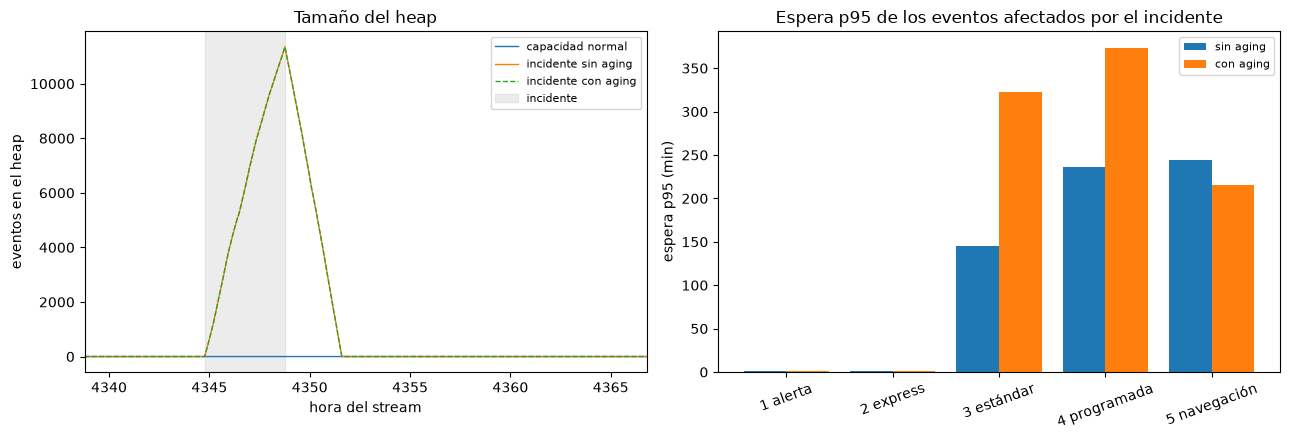

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

horas = lambda serie: np.arange(len(serie)) / 60
ax1.plot(horas(heap_normal), heap_normal, label="capacidad normal", lw=1)
ax1.plot(horas(heap_sin), heap_sin, label="incidente sin aging", lw=1)
ax1.plot(horas(heap_con), heap_con, label="incidente con aging", lw=1, ls="--")
ax1.axvspan(INCIDENTE.start / 60, INCIDENTE.stop / 60, color="gray", alpha=0.15, label="incidente")
ax1.set_xlim(INCIDENTE.start / 60 - 6, INCIDENTE.stop / 60 + 18)
ax1.set_xlabel("hora del stream"); ax1.set_ylabel("eventos en el heap")
ax1.set_title("Tamaño del heap"); ax1.legend(fontsize=8)

afectados_sin, afectados_con = afectados(atendidos_sin), afectados(atendidos_con)
clases = sorted(afectados_con["clase"].unique())
x = np.arange(len(clases))
p95_sin = [afectados_sin.loc[afectados_sin["clase"] == c, "espera_s"].quantile(0.95) / 60 for c in clases]
p95_con = [afectados_con.loc[afectados_con["clase"] == c, "espera_s"].quantile(0.95) / 60 for c in clases]
ax2.bar(x - 0.2, p95_sin, width=0.4, label="sin aging")
ax2.bar(x + 0.2, p95_con, width=0.4, label="con aging")
ax2.set_xticks(x, [NOMBRE_CLASE[c] for c in clases], rotation=20)
ax2.set_ylabel("espera p95 (min)"); ax2.set_title("Espera p95 de los eventos afectados por el incidente")
ax2.legend(fontsize=8)

plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / f"etapa2_aging_{CATEGORIA}.png", dpi=150)
plt.show()

### Espera de la navegación a lo largo del tiempo

La gráfica siguiente muestra la espera de cada evento de navegación afectado por el incidente, en el orden en que fue atendido. Permite ver cuándo se atienden los eventos acumulados durante el incidente.

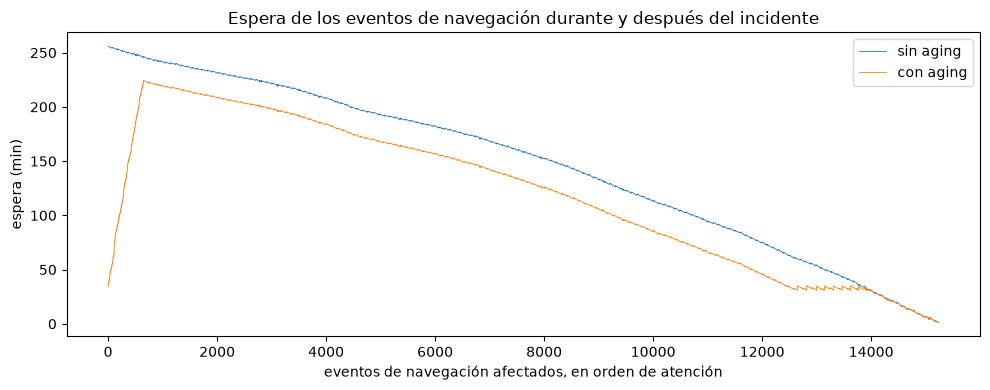

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for nombre, atendidos in [("sin aging", atendidos_sin), ("con aging", atendidos_con)]:
    nav = afectados(atendidos)
    nav = nav.loc[nav["clase"] == 5, "espera_s"].reset_index(drop=True) / 60
    ax.plot(nav.index, nav.values, lw=0.6, label=nombre)
ax.set_xlabel("eventos de navegación afectados, en orden de atención")
ax.set_ylabel("espera (min)")
ax.set_title("Espera de los eventos de navegación durante y después del incidente")
ax.legend()
plt.tight_layout()
plt.show()

### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada, con los 9 940 617 eventos limpios de `Office_Products`, que cubren 438 días del stream.

- **Capacidad normal.** Con 107 eventos por minuto, un 10 % sobre el minuto con más llegadas (97), todas las clases se atienden en un minuto o menos y al 100 % dentro de plazo, incluidas las alertas con su plazo de 5 minutos.
- **El incidente.** Cae en las horas 4 345 a 4 349 del stream, con 52 llegadas por minuto. Las clases 1 a 4 llegan a 11.2 eventos por minuto, frente a 3.3 en promedio, y solo se atienden 5. El heap llega a 11 353 eventos y tarda 2.8 horas en vaciarse después del incidente. Los eventos afectados son los 19 338 que entran al heap en esas 6.8 horas, el 0.19 % del stream.
- **Alertas y compras express.** Con y sin aging se atienden dentro de plazo, con una espera máxima de 1 minuto las alertas y de 1.9 minutos las compras express. Son pocas (43 alertas y 681 compras express afectadas) y la prioridad por clase las atiende primero.
- **Navegación sin aging.** Entre los eventos afectados, la espera media es de 146.5 minutos, el p95 de 244.2 y la máxima de 256. Los eventos de navegación acumulados solo salen cuando la capacidad se recupera.
- **Navegación con aging.** La espera media baja a 119.9 minutos (un 18 % menos), el p95 a 215.4 (un 12 % menos) y la máxima a 224.5. Los eventos que esperan más de 30 minutos suben a la clase 3 y se atienden antes que las compras estándar y programadas. Hubo 28 996 ascensos de clase.
- **El costo del aging.** Las compras estándar afectadas pasan de 55.2 a 175.8 minutos de espera media, con un máximo de 339, y las programadas de 97.8 a 214.1, con un máximo de 390. Las dos siguen al 100 % dentro de plazo, porque sus plazos son de 24 h y 72 h. El aging traslada la espera a las clases que tienen holgura.
- **Lo que el aging no resuelve.** Solo el 8 % de la navegación afectada se atiende dentro de su plazo de 30 minutos, con y sin aging, y el tamaño del heap es idéntico en los dos escenarios. Ninguna política de orden compensa la falta de capacidad; la cola de prioridades decide quién espera, pero no reduce la espera total.
- **Todo el stream.** Como el incidente afecta al 0.19 % de los eventos, en el total el 99.8 % de la navegación y el 100 % de las demás clases se atienden dentro de plazo.

En resumen, la etapa cumple el requisito del escenario B. Las alertas y las órdenes express se atienden primero aun con el sistema saturado, y el aging reduce la espera de la navegación sin poner en riesgo los plazos de ninguna orden.

## Paso 7. Experimentos de complejidad

Los experimentos de complejidad del min-heap (n push y n pop frente a `heapq` y a una lista ordenada, y construcción con `heapify` frente a n push) se hacen en un notebook aparte, `notebooks/experimentos_complejidad.ipynb`, porque llegan a 10 millones de elementos y tardan varios minutos. Ese notebook importa el `MinHeap` de `src/stage2_heap.py`, que es idéntico al de este notebook.

Resumen de los resultados, de 1K a 10M elementos con Python 3.12:

| Experimento | Método | Pendiente log-log | Esperado |
| --- | --- | --- | --- |
| n push y n pop | `MinHeap` (propio) | 1.09 | n log n |
| n push y n pop | `heapq` (C) | 1.19 | n log n |
| n push y n pop | Lista ordenada con `insort` y `pop(0)` | 1.71 | n² |
| Construcción, claves decrecientes | n `push` (propio) | 1.06 | n log n |
| Construcción, claves decrecientes | `heapify` de Floyd (propio) | 1.02 | n |

A 100K la lista ordenada ya es 4 veces más lenta que `MinHeap`, y la diferencia crece con n. En el peor caso, construir el heap con `push` costó 4.7 veces más que con `heapify` a 10M. Las tres estructuras usan entre 8 y 9 bytes por elemento.

## Paso 8. Salida de la etapa 2

La salida son los eventos **en el orden en que la etapa 2 los atiende**, con los campos `priority` y `deadline` ya asignados. Se guarda la ejecución del escenario de incidente con aging, que es la configuración adoptada. El archivo se escribe durante la simulación del paso 6, un ciclo de servicio por línea, así que los eventos atendidos no se acumulan en memoria. La celda siguiente lo vuelve a leer para comprobar que contiene todos los eventos.

Las etapas siguientes usan esta salida de distintas formas.

| Etapa | Uso |
| --- | --- |
| 3. Hash, LRU | Actualiza la caché de productos y usuarios en el orden de servicio |
| 6. Bloom Filter y Count-Min Sketch | Revisa `payment_id`, `device_id` y `user_id` contra las listas de señalados y cuenta intentos por ventana |
| 8. Grafo de co-compra | Agrupa las compras por `order_id` para crear las aristas entre productos |

El archivo es `data/interim/<CATEGORIA>/etapa2_eventos.jsonl`.

In [10]:
total = 0
with open(salida.ruta, encoding="utf-8") as archivo:
    for linea in archivo:
        total += len(json.loads(linea)["eventos"])
assert total == salida.eventos == n_eventos, "la etapa 2 debe atender todos los eventos"
print(f"{salida.ruta.relative_to(RAIZ)}: {total:,} eventos en {salida.ciclos:,} ciclos con eventos "
      f"({salida.ruta.stat().st_size / 1e9:.2f} GB)")

# Primeros eventos atendidos en el primer ciclo del incidente
pd.DataFrame([{"event_type": e.event_type, "order_type": e.order_type, "priority": e.priority,
               "order_id": e.order_id, "payment_id": e.payment_id}
              for e in salida.primer_ciclo_incidente])

data\interim\Office_Products\etapa2_eventos.jsonl: 9,940,617 eventos en 598,327 ciclos con eventos (3.58 GB)


,event_type,order_type,priority,order_id,payment_id
0,purchase,standard,3,o00734606,pay_d32f2048
1,purchase,standard,3,o00734606,pay_d32f2048
2,purchase,standard,3,o00734606,pay_d32f2048
3,purchase,standard,3,o00734606,pay_d32f2048
4,purchase,standard,3,o00734590,pay_c62067b1


### Datos para las etapas 6 y 8

Se muestran dos ejemplos de cómo las etapas siguientes pueden usar la salida.

- **Etapa 6.** Las alertas de pago salen primero en su ciclo. Se cuenta cuántas alertas tienen una tarjeta de la lista de señalados que generó la etapa 0. Las alertas que no están en la lista son las falsas alarmas que la etapa 6 debe verificar antes de bloquear.
- **Etapa 8.** Se cuentan las órdenes con más de un producto, que son las que crean aristas en el grafo de co-compra.

In [11]:
print(f"Alertas de pago atendidas: {salida.alertas:,}")
print(f"  con tarjeta señalada: {salida.alertas_con_tarjeta_senalada:,}   sin tarjeta señalada (falsas alarmas): "
      f"{salida.alertas - salida.alertas_con_tarjeta_senalada:,}")

multiproducto = sum(1 for n in salida.productos_por_orden.values() if n > 1)
print(f"\nÓrdenes de compra: {len(salida.productos_por_orden):,}   con más de un producto: {multiproducto:,}")

Alertas de pago atendidas: 15,018
  con tarjeta señalada: 11,099   sin tarjeta señalada (falsas alarmas): 3,919

Órdenes de compra: 1,335,292   con más de un producto: 324,550


## Resumen de la etapa 2

| Aspecto | Decisión |
| --- | --- |
| Estructura | Min-heap binario propio sobre un arreglo; push y pop en O(log n), heapify en O(n) |
| Clave | `(clase, deadline, seq)`: clase de urgencia, después el deadline más cercano, después el orden de llegada |
| Clases | 1 alerta de pago, 2 express, 3 estándar y devoluciones, 4 programada, 5 navegación |
| Aging | Sube una clase cada 15 min de espera, sin pasar de la clase 3; pasada cada 5 minutos del stream con heapify en O(n) |
| Memoria | Los eventos se leen del archivo de la etapa 1 en cada escenario; en memoria quedan el heap y una fila numérica por evento atendido |
| Salida | Eventos en orden de servicio con `priority` y `deadline`, en `data/interim/<CATEGORIA>/etapa2_eventos.jsonl` |

Referencias. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 6. Williams, J. W. J. (1964). Algorithm 232: Heapsort. *Communications of the ACM*, 7(6), 347-348. Floyd, R. W. (1964). Algorithm 245: Treesort 3. *Communications of the ACM*, 7(12), 701.